# TD — Régression linéaire : effet de l'âge, du sexe et des comorbidités sur la sévérité clinique initiale de l'AVC

**Master 2 — SITIS**

---

## Contexte clinique

Le score **NIHSS** (*National Institutes of Health Stroke Scale*) est l'échelle de référence pour quantifier la sévérité neurologique d'un Accident Vasculaire Cérébral (AVC) à l'admission. Il varie de **0** (aucun déficit) à **42** (déficit majeur).

Une question clinique classique est de savoir **quels facteurs, présents dès l'admission, sont associés à une sévérité initiale plus importante**. Comprendre ces déterminants permet :

- d'anticiper la gravité clinique de certains profils de patients,
- d'ajuster les analyses pronostiques ultérieures sur ces facteurs (facteurs de confusion),
- de mieux orienter la recherche étiologique.

## Objectif du TD

> **Étudier l'effet de l'âge, du sexe et des comorbidités cardiovasculaires sur le score NIHSS à l'admission, à l'aide d'un modèle de régression linéaire multiple.**

## Objectifs pédagogiques

À l'issue de ce TD, vous serez capables de :

1. Conduire une analyse descriptive rigoureuse d'un jeu de données clinique ;
2. Construire un modèle de régression linéaire multiple avec des prédicteurs continus, binaires et catégoriels ;
3. Interpréter cliniquement et statistiquement les coefficients d'un modèle linéaire ;
4. Vérifier les hypothèses sous-jacentes au modèle (linéarité, homoscédasticité, normalité des résidus, colinéarité, points influents) ;
5. Discuter les limites d'un modèle de régression appliqué à des données observationnelles.

---


## 0. Import des librairies

On utilise `statsmodels` plutôt que `scikit-learn` pour la régression linéaire : il fournit nativement les **erreurs standards, intervalles de confiance, p-values et diagnostics** nécessaires à une analyse statistique inférentielle (contrairement à `scikit-learn`, orienté prédiction).

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from IPython.display import Image, display

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (6, 4)

pd.set_option("display.max_columns", None)


## 1. Chargement et description du jeu de données

Le fichier `tbl_stroke.csv` contient les données de **1203 patients** pris en charge pour un AVC. Chaque ligne correspond à un patient.

### Dictionnaire des variables

| Variable | Type | Description |
|---|---|---|
| `patient_id` | id | Identifiant patient |
| `sex` | catégorielle | Sexe (`Male` / `Female`) |
| `age_at_inclusion` | continue | Âge à l'inclusion (années) |
| `hypertension` | binaire (0/1) | Hypertension artérielle |
| `atrial_fibrillation` | binaire (0/1) | Fibrillation atriale |
| `ischemic_heart_disease` | binaire (0/1) | Cardiopathie ischémique |
| `diabetes` | binaire (0/1) | Diabète |
| `transient_ischemic_attack` | binaire (0/1) | Antécédent d'AIT |
| `chronic_kidney_disease` | binaire (0/1) | Insuffisance rénale chronique |
| `time_to_care_hours` | continue | Délai symptômes → prise en charge (heures) |
| `stroke_location` | catégorielle | Localisation de l'AVC |
| `stroke_size` | catégorielle | Taille de la lésion |
| **`NIHSS_admission`** | **continue (score 0-42)** | **Score NIHSS à l'admission — variable d'intérêt (Y)** |
| `NIHSS_discharge` | continue | Score NIHSS à la sortie |
| `NIHSS_12_months` | continue | Score NIHSS à 12 mois |
| `stroke_within_12_months` | binaire | Récidive d'AVC à 12 mois |
| `myocardial_infarction_within_12_months` | binaire | IDM à 12 mois |
| `death_within_12_months` | binaire | Décès à 12 mois |

Pour ce TD, seules les variables en **gras** et celles servant de prédicteurs (âge, sexe, comorbidités) nous intéressent. Les autres variables (localisation, taille de lésion, devenir à 12 mois...) ne seront pas incluses dans le modèle principal — nous en reparlerons dans la discussion des limites.


In [3]:
df = pd.read_csv("tbl_stroke.csv")
print(df.shape)
df.head()


(1203, 18)


,patient_id,sex,age_at_inclusion,hypertension,atrial_fibrillation,ischemic_heart_disease,diabetes,transient_ischemic_attack,chronic_kidney_disease,time_to_care_hours,stroke_location,stroke_size,NIHSS_admission,NIHSS_discharge,NIHSS_12_months,stroke_within_12_months,myocardial_infarction_within_12_months,death_within_12_months
0,1,Male,76.169747,0,0,0,0,0,0,11,Lacunar,Small,10,0,0.0,1,0,0
1,2,Female,67.006160,0,0,0,0,0,0,3,MCA,Medium,10,1,0.0,0,0,0
2,3,Male,52.221766,1,0,0,0,0,0,1,Lacunar,Small,13,0,0.0,1,0,0
3,4,Male,60.388775,1,0,0,1,0,0,3,Vertebro_basilar,Medium,16,10,0.0,1,0,0
4,5,Male,72.851472,1,1,0,1,0,0,14,ACA,Medium,22,17,11.0,1,0,0


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1203 entries, 0 to 1202
Data columns (total 18 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   patient_id                              1203 non-null   int64  
 1   sex                                     1203 non-null   object 
 2   age_at_inclusion                        1203 non-null   float64
 3   hypertension                            1203 non-null   int64  
 4   atrial_fibrillation                     1203 non-null   int64  
 5   ischemic_heart_disease                  1203 non-null   int64  
 6   diabetes                                1203 non-null   int64  
 7   transient_ischemic_attack               1203 non-null   int64  
 8   chronic_kidney_disease                  1203 non-null   int64  
 9   time_to_care_hours                      1203 non-null   int64  
 10  stroke_location                         1203 non-null   obje

## 2. Contrôle qualité des données

Avant toute modélisation, il est indispensable de vérifier :

- l'absence de doublons dans les id des patients,
- la présence de valeurs manquantes,


In [ ]:
### A compléter is.na ; duplicated

Doublons patient_id : 0

Valeurs manquantes par variable :
patient_id                                  0
sex                                         0
age_at_inclusion                            0
hypertension                                0
atrial_fibrillation                         0
ischemic_heart_disease                      0
diabetes                                    0
transient_ischemic_attack                   0
chronic_kidney_disease                      0
time_to_care_hours                          0
stroke_location                             0
stroke_size                                 0
NIHSS_admission                             0
NIHSS_discharge                             0
NIHSS_12_months                           173
stroke_within_12_months                     0
myocardial_infarction_within_12_months      0
death_within_12_months                      0
dtype: int64


**Exercice guidé.** On constate des valeurs manquantes sur `NIHSS_12_months`. Cette variable n'est pas utilisée dans le modèle principal (qui porte sur le NIHSS **à l'admission**), donc ces données manquantes n'affectent pas notre analyse. Toutes les variables utilisées ici (âge, sexe, comorbidités, NIHSS admission) sont **complètes**.

> Montrer la description des données `NIHSS_admission` et de `age_at_inclusion`

In [ ]:
### A compléter .describe

count    1203.000000
mean       74.144736
std        11.203441
min        47.411362
25%        65.901437
50%        73.823409
75%        82.995209
max        97.546886
Name: age_at_inclusion, dtype: float64

count    1203.000000
mean       14.106401
std         6.691961
min         1.000000
25%         9.000000
50%        13.000000
75%        18.000000
max        42.000000
Name: NIHSS_admission, dtype: float64


Le score NIHSS varie de 0 à 42 :

On crée une variable `sex` en type `category` avec **`Male` comme modalité de référence**, ce qui sera important pour l'interprétation des coefficients du modèle.

> Modélisez `sex` comme une variable catégorielle

In [ ]:
### A compléter .Categorical


sex
Male      612
Female    591
Name: count, dtype: int64

**DAG associé avec le NIHSS à l'admission**

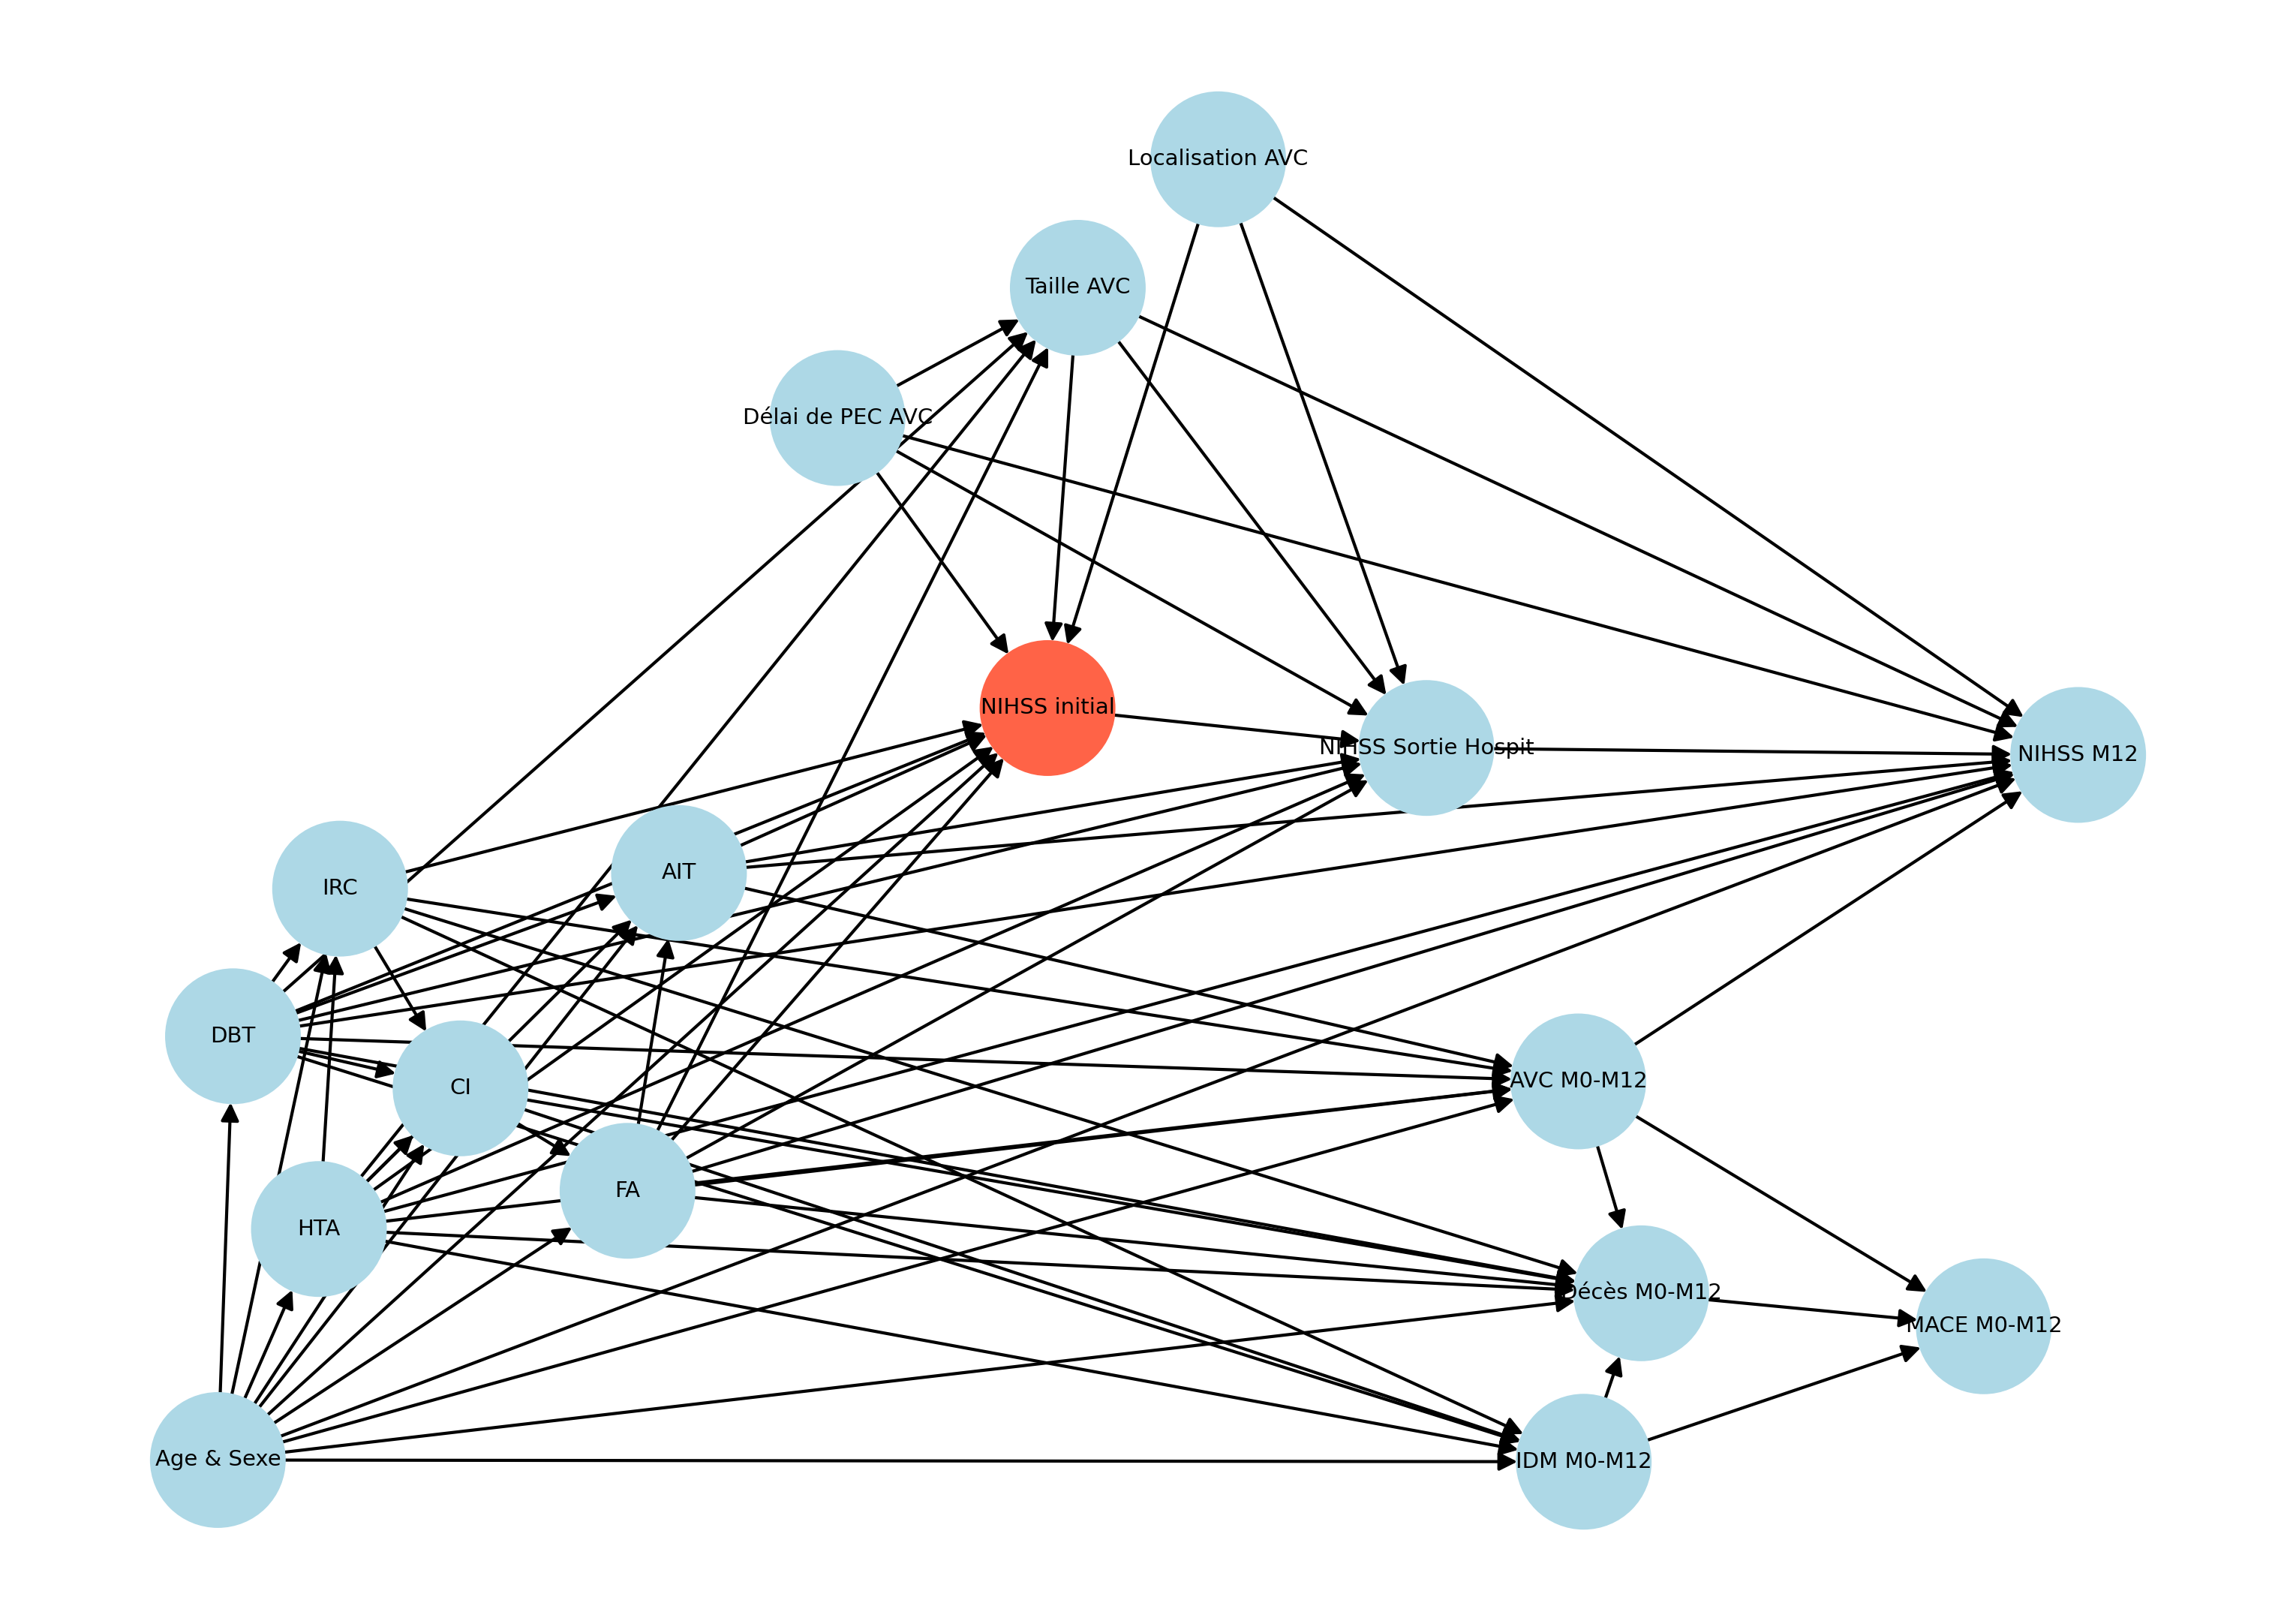

In [15]:
display(Image(filename="DAG_NIHSS_full.png"))

## 3. Analyse descriptive univariée

### 3.1 Variable d'intérêt : le NIHSS à l'admission

> Générez le graphique de la distribution de `NIHSS_admission` (histogramme) ainsi qu'un boxplot de `NIHSS_admission`

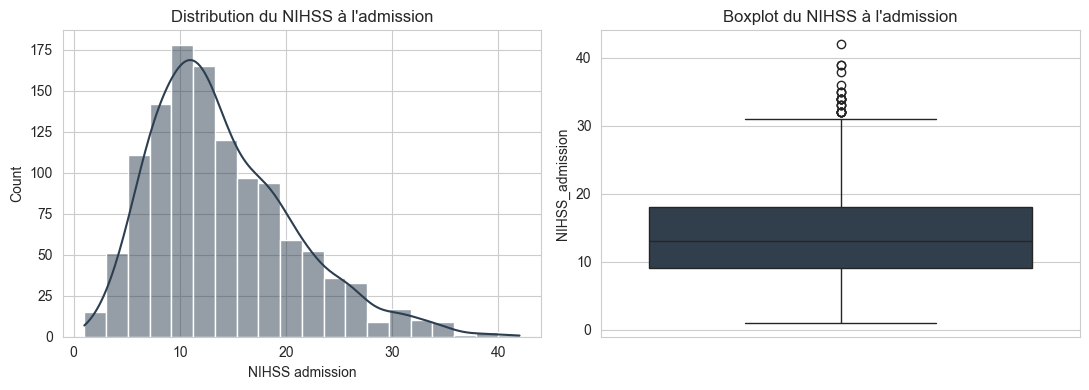

Moyenne : 14.11
Médiane : 13.0
Écart-type : 6.69


In [ ]:
### A compléter sns.histplot ; .boxplot 

> **Question** Que pouvez-vous me dire de la distribution du NIHSS ? Est-elle symétrique ?


### 3.2 Prédicteurs

> Faire la même chose pour les variables *age_at_inclusion* et *sex*. Que pouvais-vous me dire ?

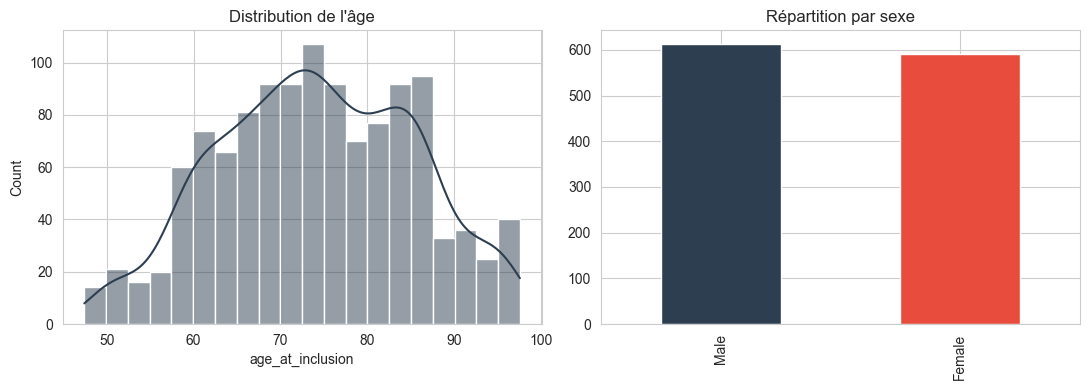

In [ ]:
### A compléter 

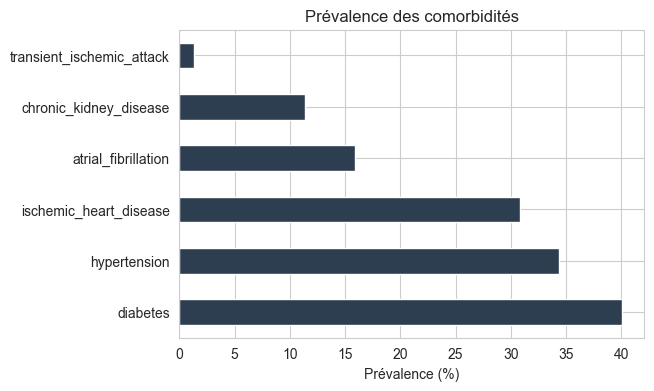

diabetes                     40.1
hypertension                 34.4
ischemic_heart_disease       30.8
atrial_fibrillation          15.9
chronic_kidney_disease       11.4
transient_ischemic_attack     1.3
dtype: float64

In [ ]:
comorbidites = ["hypertension", "atrial_fibrillation", "ischemic_heart_disease",
                "diabetes", "transient_ischemic_attack", "chronic_kidney_disease"]

# A Compléter, donner les prévalences de chaque comorbidités .mean


**Point d'attention.** La `transient_ischemic_attack` (antécédent d'AIT) ne concerne qu'environ **1 à 2 %** des patients. Qu'en pensez-vous ?


## 4. Analyse bivariée exploratoire

Avant de construire le modèle multivarié, on explore la relation entre chaque prédicteur et le NIHSS **pris isolément**. Cela permet de se faire une première idée des effets, sans encore les ajuster les uns sur les autres.

### 4.1 NIHSS et âge

> Réaliser une régression linéaire entre le NIHSS et l'*age_at_inclusion*. Générez la droite de régression et le summary du modèle, que pensez de ce modèle ?


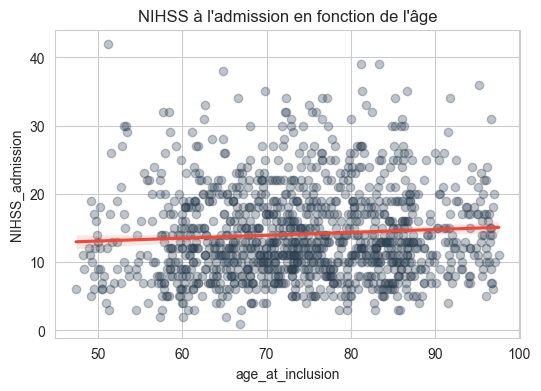

                 Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.004    
Dependent Variable: NIHSS_admission  AIC:                7984.5120
Date:               2026-10-11 23:16 BIC:                7994.6971
No. Observations:   1203             Log-Likelihood:     -3990.3  
Df Model:           1                F-statistic:        6.041    
Df Residuals:       1201             Prob (F-statistic): 0.0141   
R-squared:          0.005            Scale:              44.595   
------------------------------------------------------------------
                      Coef.  Std.Err.   t    P>|t|  [0.025  0.975]
------------------------------------------------------------------
Intercept            10.9733   1.2892 8.5117 0.0000 8.4439 13.5026
age_at_inclusion      0.0423   0.0172 2.4579 0.0141 0.0085  0.0760
------------------------------------------------------------------
Omnibus:             141.435       Durbin-Watson:          1.976  
Prob(Omnibus)

In [ ]:
### A complter sns.regplot ; smf.ols ; .summary2


### 4.2 NIHSS et sexe

> Question identique mais avec *sex*. Attention c'est un facteur. Que pouvez-dire ?

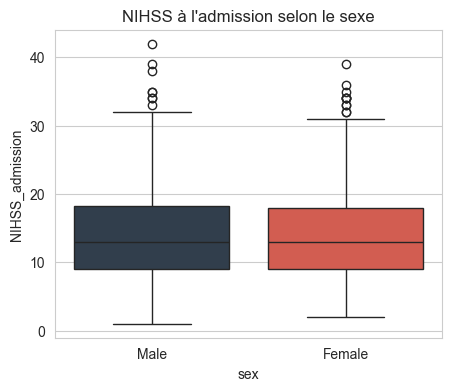

                    Coef.  Std.Err.          t          P>|t|     [0.025  \
Intercept       13.927242  0.275290  50.591224  5.997907e-300  13.387140   
C(sex)[T.Male]   0.352170  0.385964   0.912442   3.617194e-01  -0.405069   

                   0.975]  
Intercept       14.467344  
C(sex)[T.Male]   1.109409  


In [ ]:
### A compléter sns.boxplot


### 4.3 NIHSS et comorbidités

**A partir du DAG fournit plus tôt, quelles comorbidités pourraient être intégrées dans un modèle de régression linéaire multiple ? Explorez !**

## 5. Modèle de régression linéaire multiple

### 5.1 Rappel spécification du modèle

On modélise le score NIHSS à l'admission comme une fonction linéaire de l'âge, du sexe et des 6 comorbidités :

$$
\text{NIHSS}_i = \beta_0 + \beta_1\, \text{age}_i + \beta_2\, \mathbb{1}[\text{sexe}_i = \text{Femme}] + \sum_{k=1}^{6} \gamma_k\, \text{comorbidité}_{k,i} + \varepsilon_i
$$

avec $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$, indépendants.

- $\beta_1$ : effet **marginal** de l'âge (par année), **à sexe et comorbidités égaux**
- $\beta_2$ : effet du sexe féminin par rapport au sexe masculin (référence), **toutes choses égales par ailleurs**
- $\gamma_k$ : effet de chaque comorbidité, **ajusté sur toutes les autres variables du modèle**

### 5.2 Ajustement du modèle avec `statsmodels`


In [ ]:
### A Completer

### 5.3 Exercice de lecture du tableau de sortie

- **`coef`** : estimation $\hat{\beta}$ ou $\hat{\gamma}$ de chaque effet
- **`std err`** : erreur standard de l'estimation, $SE(\hat{\beta})$
- **`t`** : statistique de test $t = \hat{\beta}/SE(\hat{\beta})$, testant $H_0: \beta=0$
- **`P>|t|`** : p-value bilatérale associée
- **`[0.025  0.975]`** : intervalle de confiance à 95%

**Question 3.** Complétez le tableau suivant à partir de la sortie du modèle **avec toutes les commorbidités** (double-cliquez sur la cellule pour éditer) :

| Variable | Coefficient | IC 95% | p-value | Interprétation clinique |
|---|---|---|---|---|
| Âge (par année) | ... | ... | ... | ... |
| Sexe féminin (vs masculin) | ... | ... | ... | ... |
| Hypertension | ... | ... | ... | ... |
| Fibrillation atriale | ... | ... | ... | ... |
| Cardiopathie ischémique | ... | ... | ... | ... |
| Diabète | ... | ... | ... | ... |
| Antécédent d'AIT | ... | ... | ... | ... |
| Insuffisance rénale chronique | ... | ... | ... | ... |

**Question 4.** Le coefficient de la `transient_ischemic_attack` (AIT) a-t-il une p-value significative ? Comment expliquez-vous ce résultat au regard de la prévalence observée en section 3.2 ?


## 6. Vérification des hypothèses du modèle linéaire

Un modèle de régression linéaire n'est interprétable **que si ses hypothèses sont raisonnablement respectées** :

1. **Homoscédasticité** (variance constante des résidus)
2. **Normalité** des résidus
3. **Absence de colinéarité forte** entre prédicteurs
4. **Absence de points trop influents**

### 6.1 Résidus vs valeurs ajustées (homoscédasticité)


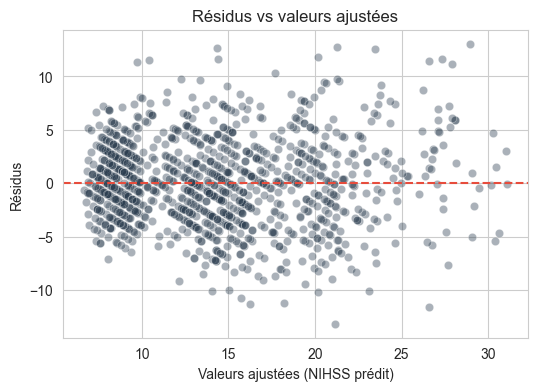

In [22]:
fitted = modele.fittedvalues
residus = modele.resid

fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(x=fitted, y=residus, alpha=0.4, color="#2C3E50", ax=ax)
ax.axhline(0, color="#E74C3C", linestyle="--")
ax.set_xlabel("Valeurs ajustées (NIHSS prédit)")
ax.set_ylabel("Résidus")
ax.set_title("Résidus vs valeurs ajustées")
plt.show()


**Question 6.** Observez-vous une structure particulière dans ce nuage de points (courbure, entonnoir) ? Que cela suggère-t-il sur la validité des hypothèses de linéarité et d'homoscédasticité ?


### 6.2 Normalité des résidus (QQ-plot)

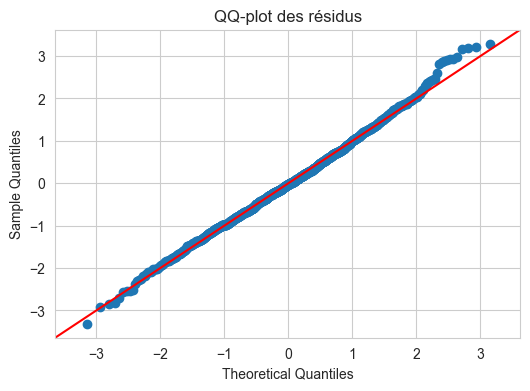

In [23]:
fig = sm.qqplot(residus, line="45", fit=True)
plt.title("QQ-plot des résidus")
plt.show()


**Question 7.** Selon vous, à partir de ce QQ-plot, est-ce que les résidus suivent une distribution normale ?


### 6.3 Points influents : distance de Cook

La **distance de Cook** du patient $i$ mesure à quel point les prédictions du modèle changeraient si ce patient était retiré de l'échantillon.

Un seuil usuel d'alerte est $D_i > \dfrac{4}{n}$.


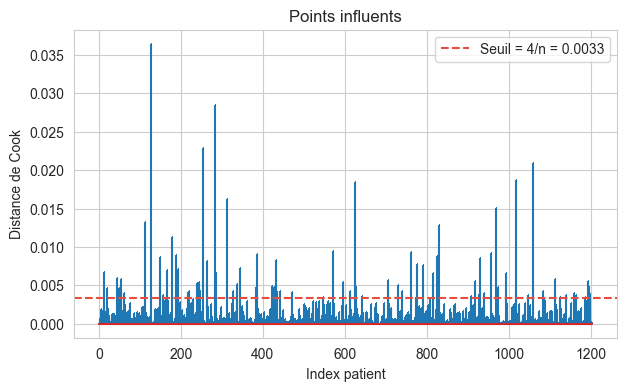

Nombre de patients au-dessus du seuil : 80 sur 1203


In [25]:
influence = modele.get_influence()
cooks_d = influence.cooks_distance[0]

seuil = 4 / len(df)
n_influents = (cooks_d > seuil).sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.stem(cooks_d, markerfmt=",")
ax.axhline(seuil, color="#E74C3C", linestyle="--", label=f"Seuil = 4/n = {seuil:.4f}")
ax.set_xlabel("Index patient")
ax.set_ylabel("Distance de Cook")
ax.set_title("Points influents")
ax.legend()
plt.show()

print(f"Nombre de patients au-dessus du seuil : {n_influents} sur {len(df)}")


### Exercice d'application : Interaction âge × sexe

L'effet de l'âge sur le NIHSS pourrait-il différer entre hommes et femmes ? Ajoutez un terme d'interaction `age_at_inclusion:C(sex)` au modèle et interprétez le coefficient d'interaction (significatif ou non).


In [ ]:
# A Compléter
# modele_interaction = smf.ols(..., data=df).fit()
# print(modele_interaction.summary())


## 7. Synthèse et discussion critique

**Question de synthèse (à rédiger, façon section « Résultats » d'un article scientifique, 8-10 lignes) :**

> Rédigez un court paragraphe résumant les facteurs associés au score NIHSS à l'admission dans cette cohorte, en précisant pour chaque facteur significatif le sens de l'effet, son amplitude (avec IC95%) et sa significativité.

### Limites de l'étude à discuter

- **Causalité** : il s'agit de données observationnelles transversales — les associations mises en évidence ne permettent pas de conclure à un lien de causalité direct.
- **Facteurs de confusion non mesurés** : la localisation (`stroke_location`) et la taille de la lésion (`stroke_size`) sont des déterminants majeurs du NIHSS, non inclus ici par choix pédagogique (ils ne sont pas des « comorbidités » mais des caractéristiques de l'AVC lui-même, potentiellement sur le chemin causal).
- **Variables rares** : la faible prévalence de l'AIT limite la puissance pour détecter un effet réel de cette variable (risque d'erreur de type II).
- **Linéarité imposée** : le modèle suppose un effet linéaire de l'âge ; une relation non linéaire (ex : effet accéléré après 80 ans) n'est pas explorée ici (pourrait faire l'objet d'un TD ultérieur sur les splines/polynômes).
